# Analytical Formulation for CHS Base-Plate Compression and Anchor-Bolt Tension

## 1. Objective and assumptions

The objective is to determine the compressive force and bending moment developed by a CHS cross-section and combine them with the anchor-bolt tensile forces to satisfy equilibrium.

Three approaches are considered:

1. **Thin-wall approximation:** the stress is integrated around the CHS circumference at its mean radius.
2. **Thickness-corrected approximation:** the strain and stress vary through the CHS wall thickness.

Assume linear elastic material behaviour:

$$
\sigma=E\varepsilon,
\qquad
\varepsilon_{\max}=\frac{f_y}{E}.
$$

For CHS 610 × 6.3 mm (the section used in the code cells):

| Parameter | Value |
|---|---:|
| Outer diameter, \(D\) | 610 mm |
| Wall thickness, \(t\) | 6.3 mm |
| Outer radius, \(R_o\) | 305 mm |
| Inner radius, \(R_i\) | 298.7 mm |
| Young's modulus, \(E\) | 210,000 MPa |
| Yield strength, \(f_y\) | 275 MPa |

The formulations below assume that compression is the only stress contribution retained in the section model. This is a modelling idealisation; ordinary elastic bending of steel generally produces both tensile and compressive stresses.

---

## 2. Approach 1 — Thin-wall approximation

Assume that the entire CHS wall is concentrated at its mean radius:

$$
R_m=R_o-\frac{t}{2}.
$$

The strain distribution is defined by

$$
\varepsilon(\theta)=
\varepsilon_{\max}
\frac{\cos\theta-\cos\theta_0}
{1-\cos\theta_0},
$$

where $\theta_0$ is the assumed angular boundary of the compression region.

The stress is

$$
\sigma(\theta)=E\varepsilon(\theta).
$$

The differential area is

$$
dA=R_m t\,d\theta.
$$

### 2.1 Axial compressive force

$$
N_c=\int_{-\theta_0}^{\theta_0}\sigma(\theta)\,dA.
$$

After integration:

$$
\boxed{
N_c=
\frac{2E\varepsilon_{\max}R_m t}
{1-\cos\theta_0}
\left(\sin\theta_0-\theta_0\cos\theta_0\right)
}
$$

### 2.2 Moment about the CHS centre

The moment arm is $R_m\cos\theta$:

$$
M_c=\int_{-\theta_0}^{\theta_0}
\sigma(\theta)R_m\cos\theta\,dA.
$$

Therefore,

$$
\boxed{
M_c=
\frac{E\varepsilon_{\max}R_m^2t}
{1-\cos\theta_0}
\left(\theta_0-\sin\theta_0\cos\theta_0\right)
}
$$

Use radians for $\theta_0$.

---

## 3. Approach 2 —  Thickness-corrected

Neutral axis at $y_{NA}=R_o\cos\theta_0$ (straight line), $y=r\cos\theta$, maximum compressive strain $\varepsilon_{\max}$ at $y=R_o$:

$$
\varepsilon=\varepsilon_{\max}\frac{y-y_{NA}}{R_o-y_{NA}},
\qquad
k=\frac{E\,\varepsilon_{\max}}{R_o-y_{NA}} .
$$

At radius $r$ the compressed arc is $|\theta|\le\alpha(r)$ with $\cos\alpha=y_{NA}/r$ (so $\alpha=\pi$, a full circle, when $r\le -y_{NA}$). Write $c=y_{NA}$ and $u=\sqrt{r^2-c^2}$. Integrating over $\theta$:

$$
N_c=k\int 2r\,(r\sin\alpha-c\,\alpha)\,dr,
\qquad
M_c=k\int r\left[r^2(\alpha+\sin\alpha\cos\alpha)-2rc\sin\alpha\right]dr .
$$

Using $r\sin\alpha=u$ and $r\cos\alpha=c$ the integrands reduce to $2r(u-c\alpha)$ and $r^3\alpha-c\,r\,u$, which have closed-form antiderivatives:

$$
F_N(r)=\tfrac23u^3-c\,r^2\alpha+c^2u,
\qquad
F_M(r)=\tfrac14r^4\alpha-\tfrac{5}{12}c\,u^3-\tfrac14c^3u .
$$

**Partial arcs** ($r_{lo}=\max(R_i,c)\le r\le R_o$):

$$
\boxed{N_c=k\,[F_N(R_o)-F_N(r_{lo})]},
\qquad
\boxed{M_c=k\,[F_M(R_o)-F_M(r_{lo})]} .
$$

**Full circles** (only if $c<0$ and $R_i<-c$, for $R_i\le r\le\min(-c,R_o)$) add

$$
\Delta N_c=-\pi k\,c\,(r_f^2-R_i^2),
\qquad
\Delta M_c=\tfrac{\pi}{4}k\,(r_f^4-R_i^4),
\qquad r_f=\min(-c,R_o),
$$

and the partial-arc range then starts at $r_{lo}=r_f$. No numerical quadrature is needed.

---

## 4. Equilibrium with anchor bolts

Convention: **compression positive**, $y$ measured from the CHS centre, $+y$ on the compressed side, bolt tension $T_i>0$ as a magnitude.

$$
\boxed{N_{Ed}=N_c-\sum_i T_i}
\qquad
\boxed{M_{Ed}=M_c-\sum_i T_i\,y_i}
$$

(in the code $T$ is stored negative for tension, so $N_{int}=N_c+\sum T$, $M_{int}=M_c+\sum Ty$, and the residual is $\text{ext}-\text{int}$.)

**Strain field with the neutral axis anywhere.** The section strain is

$$
\varepsilon(y)=\varepsilon_0+\kappa\,y,\qquad y_{NA}=-\varepsilon_0/\kappa ,
$$

(compression positive, $\kappa>0$: compression on the $+y$ side; $\kappa<0$ is the mirror image; $\kappa=0$ is uniform axial strain). Writing $c=y_{NA}$, $N_c=E\kappa\,I_N(c)$ and $M_c=E\kappa\,I_M(c)$ with the closed forms of Approach 2 hold for **any** $c$:

| Neutral axis | Compressed CHS | Notes |
|---|---|---|
| $y_{NA}\ge R_o$ | none, $N_c=M_c=0$ | only bolts act (tension side) |
| $\lvert y_{NA}\rvert<R_o$ | partial annulus | as before |
| $y_{NA}\le -R_o$ | whole annulus: $N_c=-\pi E\kappa\,c\,(R_o^2-R_i^2)$, $M_c=\tfrac{\pi}{4}E\kappa(R_o^4-R_i^4)$ | bolts with $y_i<y_{NA}$ (possible while $-R_1<y_{NA}$) are still in tension |
| $\kappa\to 0$ | uniform strain | $N_c=E\varepsilon_0\pi(R_o^2-R_i^2)=N_{pl}$ for $\varepsilon_0=f_y/E$ |

**Maximum permitted strains (capacity).** For a given $y_{NA}$ the largest curvature is limited by the CHS (outer fibre, only if $y_{NA}<R_o$) and by the most strained bolt (only if some bolt has $y_i<y_{NA}$):

$$
\kappa_{\max}=\min\!\left(\frac{f_y/E}{R_o-y_{NA}},\;\frac{\varepsilon_{b,lim}}{y_{NA}-y_{i,\min}}\right).
$$

Whichever is smaller governs (`governing` = `'CHS'` or `'bolt'`). Sweeping $y_{NA}$ from $-\infty$ (whole section compressed, $N=N_{pl}$) through the section to $+\infty$ (all bolts at $\varepsilon_{b,lim}$, pure tension) and repeating for the mirrored bending direction gives the **closed N–M interaction diagram**. A demand $(N_{Ed},M_{Ed})$ is acceptable if it lies inside the boundary. The bolt limit must **not** be used as the strain amplitude itself.

The equilibrium solver uses $(\varepsilon_0,\kappa)$ as unknowns, so it also finds solutions with the neutral axis outside the section and pure axial states.

---

## 5. Recommended approach

- **Approach 1:** preliminary / hand checks (thin wall).
- **Approach 2:** general

## 6. Assumptions to be aware of

- The "compression" material (E, limit strain) is steel here. If this is really the **bearing zone on concrete**, E and the strain limit should be those of the concrete/grout (and the effective width is `wspread`, not necessarily $t$).
- Bolt strain is taken equal to the section strain at the bolt location (same gauge length). Real bolts have a free length $L_b$, so their elongation is $\varepsilon L_c/L_b$ — this changes the bolt stiffness a lot.
- Use the **tensile stress area** $A_s$ of the bolt (M20: 245 mm², M24: 353 mm²), not $\pi d^2/4$, and the design resistance $0.9f_{ub}A_s/\gamma_{M2}$ as the limit.
- Prying and base-plate bending are not included.


In [1]:
import numpy as np

# ---------------------------------------------------------------------------
# Strain field (plane section, compression +):  eps(y) = eps0 + kappa*y
#   neutral axis  yNA = -eps0/kappa   (may lie OUTSIDE the section)
#     yNA >= Ro  : no CHS compression (bolts only)
#     |yNA| < Ro : NA cuts the CHS
#     yNA <= -Ro : whole CHS compressed (bolts on the far side may still be in tension
#                  while -R1 < yNA)
#     kappa = 0  : uniform strain (pure axial)
# Closed-form integrals of the compressed annulus (c = yNA, u = sqrt(r^2-c^2),
# alpha = arccos(c/r)):
#   F_N(r) = 2/3 u^3 - c r^2 alpha + c^2 u
#   F_M(r) = r^4 alpha/4 - 5/12 c u^3 - 1/4 c^3 u
#   full-circle part (r <= -c, only if c < 0):  N: -pi c r^2 ,  M: pi r^4/4
# ---------------------------------------------------------------------------

def _FN(r, c):
    u  = np.sqrt(max(r*r - c*c, 0.0)); al = np.arccos(np.clip(c/r, -1, 1))
    return (2/3)*u**3 - c*r*r*al + c*c*u
def _FM(r, c):
    u  = np.sqrt(max(r*r - c*c, 0.0)); al = np.arccos(np.clip(c/r, -1, 1))
    return r**4*al/4 - (5/12)*c*u**3 - 0.25*c**3*u

def compression_zone(yNA, Ro, Ri):
    """int over the compressed annulus (y > yNA) of (y-yNA) dA and (y-yNA)*y dA.
       Valid for ANY yNA:  yNA >= Ro -> nothing compressed (0, 0)
                           yNA <= -Ro -> whole annulus compressed"""
    c = yNA; I_N = I_M = 0.0
    r_lo = max(Ri, c)
    if r_lo >= Ro:
        return 0.0, 0.0
    if c < 0 and Ri < -c:
        r_f  = min(-c, Ro)
        I_N += -np.pi*c*(r_f**2 - Ri**2)
        I_M += np.pi*(r_f**4 - Ri**4)/4
        r_lo = r_f
    if r_lo < Ro:
        I_N += _FN(Ro, c) - _FN(r_lo, c)
        I_M += _FM(Ro, c) - _FM(r_lo, c)
    return I_N, I_M

def chs_bolts_state_eps(eps0, kappa, R1, theta_bolts, Ro, Ri, A_bolt,
                        E_chs=210e3, E_bolt=210e3):
    """CHS bearing zone + elastic bolts for the strain field eps(y) = eps0 + kappa*y.
    Sign convention: compression +, y from CHS centre, bolt tension NEGATIVE,
    N_int = Nc + sum(T), M_int = Mc + sum(T*y);  equilibrium: ext = int."""
    tb = np.deg2rad(np.asarray(theta_bolts, float))
    A  = np.broadcast_to(np.asarray(A_bolt, float), tb.shape)
    y_b   = R1*np.cos(tb)
    eps_b = eps0 + kappa*y_b
    T_bolts = -E_bolt*A*np.maximum(-eps_b, 0.0)

    if abs(kappa) < 1e-30:                         # uniform strain
        Nc = E_chs*eps0*np.pi*(Ro**2 - Ri**2) if eps0 > 0 else 0.0
        Mc = 0.0
        yNA = np.inf*np.sign(-eps0) if eps0 != 0 else np.nan
    else:
        s, k = np.sign(kappa), abs(kappa)
        yNA  = -eps0/kappa
        I_N, I_M = compression_zone(s*yNA, Ro, Ri)   # work in y' = s*y, kappa' = k > 0
        Nc, Mc = E_chs*k*I_N, s*E_chs*k*I_M
    N_bolts = T_bolts.sum(); M_bolts = (T_bolts*y_b).sum()
    return dict(yNA=yNA, eps0=eps0, kappa=kappa,
                epsmax_chs=eps0 + abs(kappa)*Ro,
                N_compression=Nc, M_compression=Mc, T_bolts=T_bolts, eps_bolt=eps_b,
                N_bolts=N_bolts, M_bolts=M_bolts,
                N_int=Nc+N_bolts, M_int=Mc+M_bolts)

def chs_bolts_state(theta0, eps_chs, R1, theta_bolts, Ro, Ri, A_bolt,
                    E_chs=210e3, E_bolt=210e3, eps_bolt_lim=None):
    """Same, parametrised by the NA angle theta0 (yNA = Ro cos(theta0)) and the outer-fibre
    strain eps_chs.  eps_bolt_lim (optional) caps the strain so that no bolt exceeds it."""
    yNA = Ro*np.cos(np.deg2rad(theta0)); y_b = R1*np.cos(np.deg2rad(np.asarray(theta_bolts,float)))
    kappa = eps_chs/(Ro - yNA); governing = "CHS"
    max_t = np.max(np.maximum(yNA - y_b, 0.0)) if y_b.size else 0.0
    if eps_bolt_lim is not None and max_t > 0 and kappa*max_t > eps_bolt_lim:
        kappa, governing = eps_bolt_lim/max_t, "bolt"
    s = chs_bolts_state_eps(-kappa*yNA, kappa, R1, theta_bolts, Ro, Ri, A_bolt, E_chs, E_bolt)
    s['governing'] = governing
    return s

def capacity_state(yNA, side, R1, theta_bolts, Ro, Ri, A_bolt,
                   eps_chs_lim, eps_bolt_lim, E_chs=210e3, E_bolt=210e3):
    """Largest strain state for a given NA position yNA: kappa = min(CHS limit, bolt limit).
    side=+1: compression on +y ; side=-1: mirror image (compression on -y)."""
    th = np.asarray(theta_bolts, float)
    th_m = th if side > 0 else 180.0 - th
    y_b = R1*np.cos(np.deg2rad(th_m))
    k_chs = eps_chs_lim/(Ro - yNA) if yNA < Ro else np.inf
    max_t = np.max(np.maximum(yNA - y_b, 0.0)) if y_b.size else 0.0
    k_b   = eps_bolt_lim/max_t if max_t > 0 else np.inf
    kappa = min(k_chs, k_b)
    if not np.isfinite(kappa): return None
    s = chs_bolts_state_eps(-kappa*yNA, kappa, R1, th_m, Ro, Ri, A_bolt, E_chs, E_bolt)
    s['governing'] = "CHS" if k_chs <= k_b else "bolt"
    s['yNA'] = yNA
    if side < 0:
        for key in ('M_compression','M_bolts','M_int'): s[key] = -s[key]
    return s

def interaction_curve(R1, theta_bolts, Ro, Ri, A_bolt, eps_chs_lim, eps_bolt_lim,
                      E_chs=210e3, E_bolt=210e3, n=1500):
    """Sweeps yNA from -infinity (whole section compressed) to +infinity (bolts only), for
    both bending directions.  Returns list of (side, yNA, state)."""
    phi = np.linspace(1e-9, np.pi-1e-9, n)
    yNAs = -Ro/np.tan(phi)                         # -inf ... 0 ... +inf
    rows = []
    for side in (+1, -1):
        for y in yNAs:
            s = capacity_state(y, side, R1, theta_bolts, Ro, Ri, A_bolt,
                               eps_chs_lim, eps_bolt_lim, E_chs, E_bolt)
            if s is not None: rows.append((side, y, s))
    return rows

In [2]:
Ro, Ri = 305., 305-6.3
# (a) 
s = chs_bolts_state(90, 275/210e3, 350, [180, 100, -100], Ro, Ri, np.pi*24**2/4,
                    eps_bolt_lim=640/210e3)
print("Nc, Mc, 2Mc =", s['N_compression']/1e3, "kN ;", s['M_compression']/1e6 , "kNm", 2*s['M_compression']/1e6, "kNm", s['governing'])
# (b) pure bending, no bolts: 2*Mc must equal fy*Wel = 490.84 kNm
s = chs_bolts_state(90, 275/210e3, 350, [], Ro, Ri, 0)
print("2*Mc =", 2*s['M_compression']/1e6, "kNm   (Eurocode Wel*fy = 490.84)")
# (c) bolt strain cap governs
s = chs_bolts_state(30, 275/210e3, 350, [180], Ro, Ri, 245., eps_bolt_lim=0.002)
print("Nc = ", s['N_compression']/1e3, "kN ; Mc = ", s['M_compression']/1e6, "kNm, cap test: governing =", s['governing'], "| bolt strain =", -s['eps_bolt'][0], "(limit 0.002)")
# (d) NA OUTSIDE the section: whole CHS compressed -> N = fy*A (Npl), M = 0
A_chs = np.pi*(Ro**2 - Ri**2)
s = capacity_state(-1e9, +1, 350, np.arange(0, 360, 45), Ro, Ri, 245., 275/210e3, 0.002)
print("yNA -> -inf :  N =", s['N_int']/1e3, "kN   (fy*A =", 275*A_chs/1e3, ")")
# (e) NA outside on the other side: no CHS compression, all bolts at the strain limit
s = capacity_state(+1e9, +1, 350, np.arange(0, 360, 45), Ro, Ri, 245., 275/210e3, 0.002)
print("yNA -> +inf :  N =", s['N_int']/1e3, "kN   (8*A*E*eps_b =", -8*245*210e3*0.002/1e3, ")")


s = capacity_state(+1e9, +1, 350, np.arange(0, 360, 90), Ro, Ri, 245., 275/210e3, 0.002)
print("yNA -> +inf :  N =", s['N_int']/1e3, "kN   (4*A*E*eps_b =", -4*245*210e3*0.002/1e3, ")")
s = capacity_state(-1e9, +1, 350, np.arange(0, 360, 45), Ro, Ri, 245., 355/210e3, 0.002)
print("yNA -> -inf :  N =", s['N_int']/1e3, "kN   (fy*A =", 355*A_chs/1e3, ")")

Nc, Mc, 2Mc = 1035.1458014754137 kN ; 245.4223525475929 kNm 490.8447050951858 kNm CHS
2*Mc = 490.8447050951858 kNm   (Eurocode Wel*fy = 490.84)
Nc =  32.933426137605544 kN ; Mc =  9.694339831614435 kNm, cap test: governing = bolt | bolt strain = 0.002 (limit 0.002)
yNA -> -inf :  N = 3285.822955538273 kN   (fy*A = 3285.8239577142745 )
yNA -> +inf :  N = -823.1997118801008 kN   (8*A*E*eps_b = -823.2 )
yNA -> +inf :  N = -411.5998559400504 kN   (4*A*E*eps_b = -411.6 )
yNA -> -inf :  N = 4241.698724422135 kN   (fy*A = 4241.700018140245 )


pure compression  N =   3285.8 kN   (fy*A = 3285.8)
pure bolt tension N =   -823.2 kN
max moment        M =    306.9 kNm  (at N = 663 kN)
demand N =    -200 kN, M =   150 kNm  ->  OUTSIDE (fails)
demand N =     500 kN, M =   250 kNm  ->  INSIDE (OK)
demand N =    3000 kN, M =   400 kNm  ->  OUTSIDE (fails)
demand N =    -100 kN, M =  -150 kNm  ->  OUTSIDE (fails)


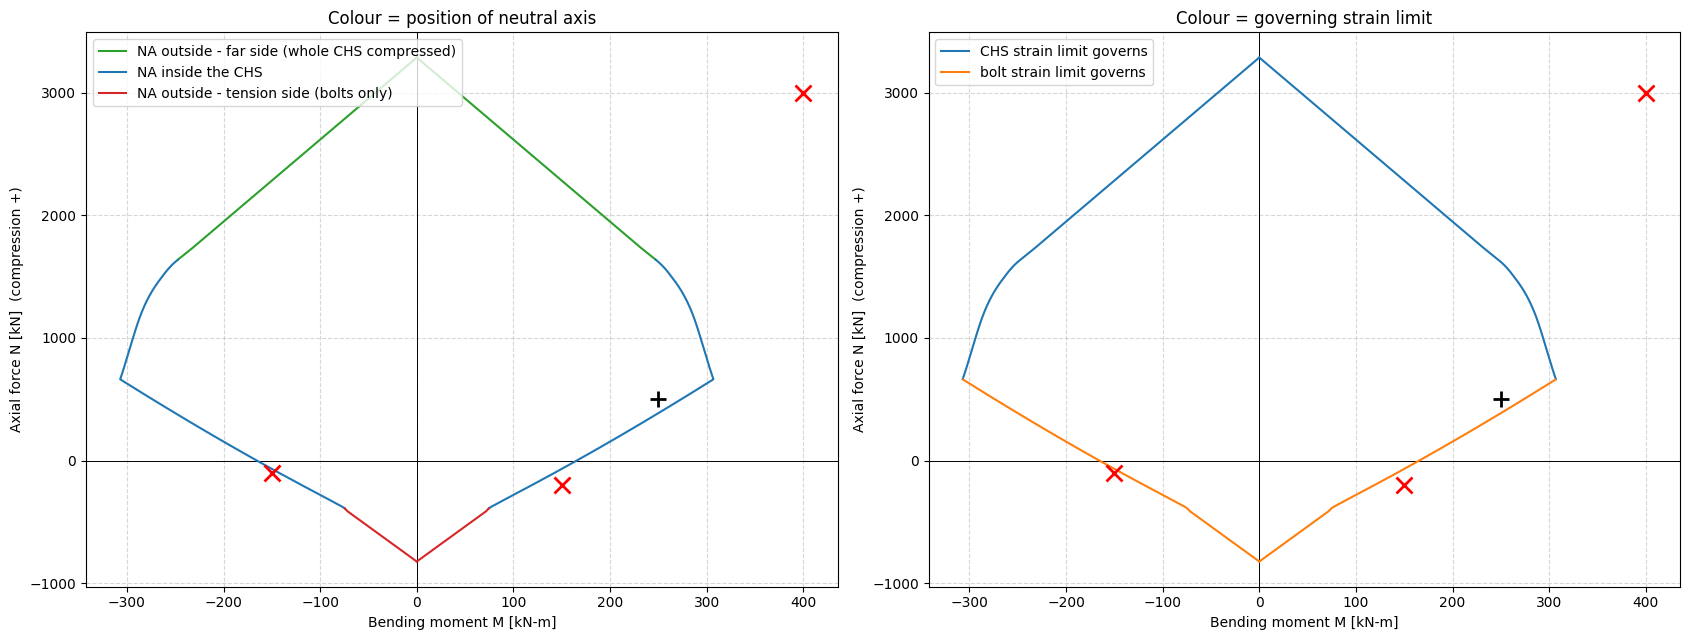

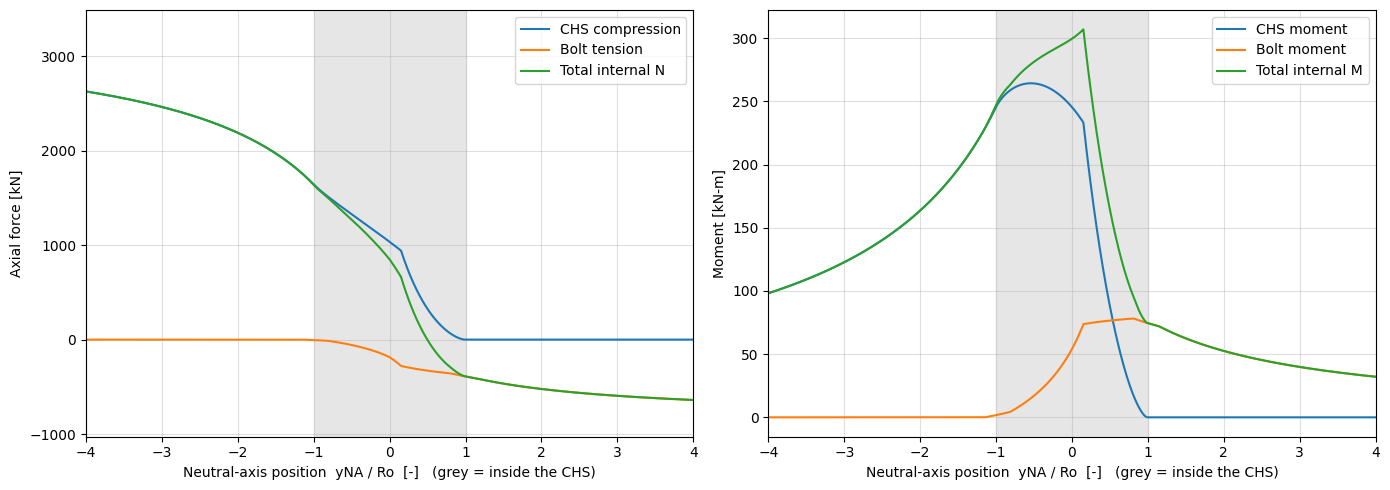

In [3]:
import matplotlib.pyplot as plt
from matplotlib.path import Path

D_CHS = 610.0          # Outer diameter [mm]
t_CHS = 6.3           # Wall thickness [mm]
Ro = D_CHS / 2.0       # Outer radius [mm]
Ri = Ro - t_CHS        # Inner radius [mm]

E_chs  = 210000.0      # [N/mm2]
E_bolt = 210000.0      # [N/mm2]
fy_chs = 275.0         # CHS yield strength [N/mm2]

epsmax_chs  = fy_chs / E_chs
epsmax_bolt = 0.002    # Maximum permitted bolt tensile strain

R1 = 350.0             # Bolt-circle radius [mm]
theta_bolts = np.array([0, 45, 90, 135, 180, 225, 270, 315], dtype=float)
A_bolt = 245.0         # Effective tensile area per bolt [mm2]

# External actions to be checked against the diagram (N compression +, M in N.mm)
demands = [(-200e3, 150e6), (500e3, 250e6), (3000e3, 400e6), (-100e3, -150e6)]

# --------------------------------------------------
# Sweep the neutral axis over the WHOLE range  -inf < yNA < +inf  (both bending directions)
# --------------------------------------------------
rows = interaction_curve(R1, theta_bolts, Ro, Ri, A_bolt, epsmax_chs, epsmax_bolt,
                         E_chs=E_chs, E_bolt=E_bolt, n=2000)

side = np.array([r[0] for r in rows]);     yNA = np.array([r[1] for r in rows])
N  = np.array([r[2]['N_int'] for r in rows]);  M  = np.array([r[2]['M_int'] for r in rows])
Nc = np.array([r[2]['N_compression'] for r in rows]); Mc = np.array([r[2]['M_compression'] for r in rows])
Nb = np.array([r[2]['N_bolts'] for r in rows]);       Mb = np.array([r[2]['M_bolts'] for r in rows])
gov_bolt = np.array([r[2]['governing'] == "bolt" for r in rows])

zone_tension = yNA >= Ro            # NA beyond the compressed edge: bolts only
zone_inside  = np.abs(yNA) < Ro     # NA cuts the CHS
zone_full    = yNA <= -Ro           # NA beyond the far edge: whole CHS compressed

# closed boundary: side +1 from full compression to pure tension, then side -1 back
p = side > 0; m = side < 0
poly = np.column_stack([np.r_[M[p], M[m][::-1]], np.r_[N[p], N[m][::-1]]])
boundary = Path(poly)

print(f"pure compression  N = {N.max()/1e3:8.1f} kN   (fy*A = {fy_chs*np.pi*(Ro**2-Ri**2)/1e3:.1f})")
print(f"pure bolt tension N = {N.min()/1e3:8.1f} kN")
print(f"max moment        M = {M.max()/1e6:8.1f} kNm  (at N = {N[np.argmax(M)]/1e3:.0f} kN)")
for Ne, Me in demands:
    inside = boundary.contains_point((Me, Ne))
    print(f"demand N = {Ne/1e3:7.0f} kN, M = {Me/1e6:5.0f} kNm  ->  {'INSIDE (OK)' if inside else 'OUTSIDE (fails)'}")

# --------------------------------------------------
# N-M interaction diagram
# --------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
for a, title in zip(ax, ["Colour = position of neutral axis", "Colour = governing strain limit"]):
    a.axhline(0, color="black", lw=0.7); a.axvline(0, color="black", lw=0.7)
    a.set_xlabel("Bending moment M [kN-m]"); a.set_ylabel("Axial force N [kN]  (compression +)")
    a.set_title(title); a.grid(True, ls="--", alpha=0.5)

for sgn in (+1, -1): # [+1]:#
    s_ = side == sgn
    for mask, col, lab in ((zone_full,    "tab:green",  "NA outside - far side (whole CHS compressed)"),
                           (zone_inside,  "tab:blue",   "NA inside the CHS"),
                           (zone_tension, "tab:red",    "NA outside - tension side (bolts only)")):
        ax[0].plot(M[s_ & mask]/1e6, N[s_ & mask]/1e3, c=col, label=lab if sgn > 0 else None)
    ax[1].plot(M[s_ & ~gov_bolt]/1e6, N[s_ & ~gov_bolt]/1e3, c="tab:blue",
                  label="CHS strain limit governs" if sgn > 0 else None)
    ax[1].plot(M[s_ & gov_bolt]/1e6,  N[s_ & gov_bolt]/1e3, c="tab:orange",
                  label="bolt strain limit governs" if sgn > 0 else None)
for a in ax:
    for Ne, Me in demands:
        ok = boundary.contains_point((Me, Ne))
        a.plot(Me/1e6, Ne/1e3, "k+" if ok else "rx", ms=11, mew=2)
    a.legend(loc="upper left")
plt.tight_layout(); plt.show()

# --------------------------------------------------
# Contributions along the sweep (bending direction +), versus NA position
# --------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x = yNA[p]/Ro
ax[0].plot(x, Nc[p]/1e3, label="CHS compression"); ax[0].plot(x, Nb[p]/1e3, label="Bolt tension")
ax[0].plot(x, N[p]/1e3, label="Total internal N"); ax[0].set_ylabel("Axial force [kN]")
ax[1].plot(x, Mc[p]/1e6, label="CHS moment"); ax[1].plot(x, Mb[p]/1e6, label="Bolt moment")
ax[1].plot(x, M[p]/1e6, label="Total internal M"); ax[1].set_ylabel("Moment [kN-m]")
for a in ax:
    a.axvspan(-1, 1, color="0.9", zorder=0)           # NA inside the section
    a.set_xlim(-4, 4); a.set_xlabel("Neutral-axis position  yNA / Ro  [-]   (grey = inside the CHS)")
    a.grid(True, alpha=0.4); a.legend()
plt.tight_layout(); plt.show()

In [4]:
def simpleInteraction(R1, theta_bolts, Ro, Ri, A_bolt, eps_chs_lim, eps_bolt_lim,
                                          E_chs=210e3, E_bolt=210e3, n=1500):
    yNAs = np.linspace(-Ro,Ro, n) 
    rows = []
    for y in yNAs:
        s = capacity_state(y, +1, R1, theta_bolts, Ro, Ri, A_bolt,
                           eps_chs_lim, eps_bolt_lim, E_chs, E_bolt)
        if s is not None: rows.append((y, s))
    return rows

Npl_CHS =  3285.8 kN, Mel_CHS = 490.8 kN-m
pure compression  N =   1637.9 kN   (fy*A = 3285.8)
pure bolt tension N =   -390.4 kN
max moment        M =    306.8 kNm  (at N = 666 kN)
demand N =    -200 kN, M =   150 kNm  ->  OUTSIDE (fails)
demand N =     500 kN, M =   250 kNm  ->  INSIDE (OK)


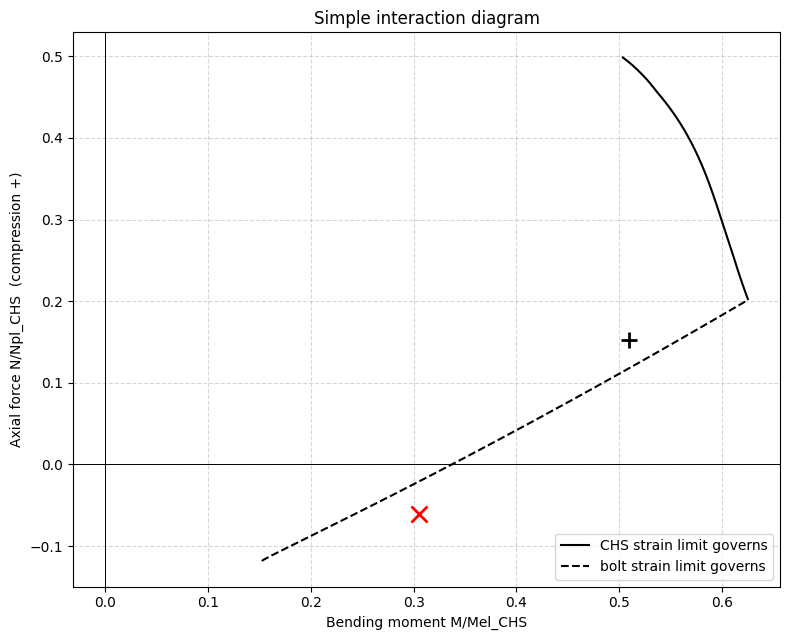

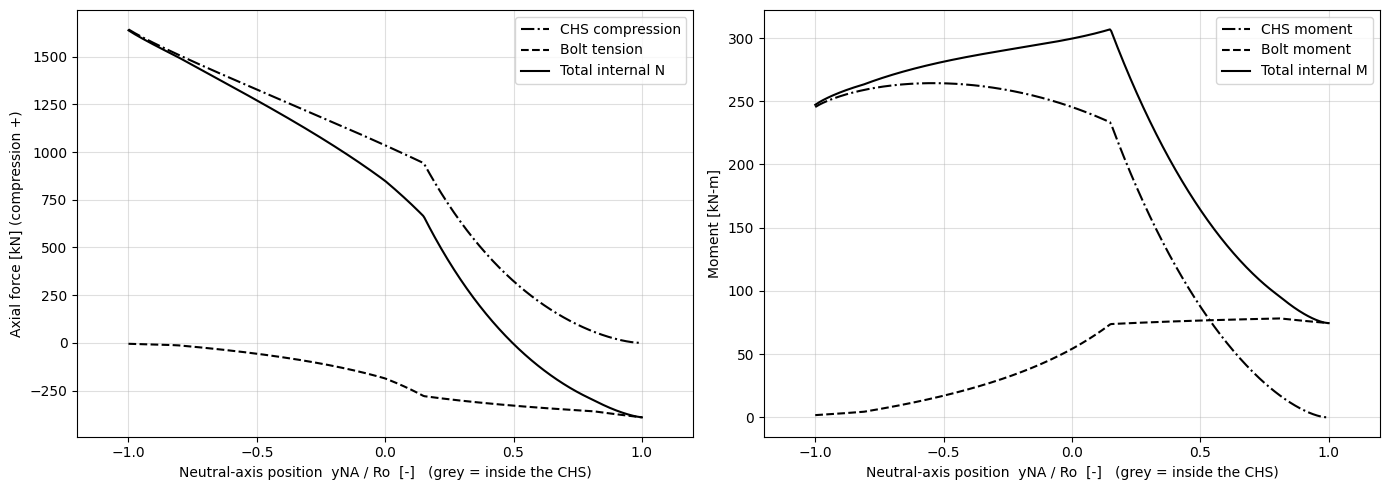

In [5]:
Ro = D_CHS / 2.0       # Outer radius [mm]
Ri = Ro - t_CHS        # Inner radius [mm]

Achs = np.pi*(Ro**2-Ri**2)
Wel = np.pi/(4*Ro)*(Ro**4-Ri**4)

Npl = Achs*fy_chs
Mely = Wel*fy_chs
print(f"Npl_CHS = {Npl/1e3:7.1f} kN, Mel_CHS = {Mely/1e6:5.1f} kN-m")

# External actions to be checked against the diagram (N compression +, M in N.mm)
demands = [(-200e3, 150e6), (500e3, 250e6)]

# --------------------------------------------------
# Sweep the neutral axis over the WHOLE range  -inf < yNA < +inf  (both bending directions)
# --------------------------------------------------
rows = simpleInteraction(R1, theta_bolts, Ro, Ri, A_bolt, epsmax_chs, epsmax_bolt,
                         E_chs=E_chs, E_bolt=E_bolt, n=400)

yNA = np.array([r[0] for r in rows])
N  = np.array([r[1]['N_int'] for r in rows]);  M  = np.array([r[1]['M_int'] for r in rows])
Nc = np.array([r[1]['N_compression'] for r in rows]); Mc = np.array([r[1]['M_compression'] for r in rows])
Nb = np.array([r[1]['N_bolts'] for r in rows]);       Mb = np.array([r[1]['M_bolts'] for r in rows])
gov_bolt = np.array([r[1]['governing'] == "bolt" for r in rows])


poly = np.column_stack([M[:]/Mely, N[:]/Npl])
boundary = Path(poly)

print(f"pure compression  N = {N.max()/1e3:8.1f} kN   (fy*A = {fy_chs*np.pi*(Ro**2-Ri**2)/1e3:.1f})")
print(f"pure bolt tension N = {N.min()/1e3:8.1f} kN")
print(f"max moment        M = {M.max()/1e6:8.1f} kNm  (at N = {N[np.argmax(M)]/1e3:.0f} kN)")
for Ne, Me in demands:
    inside = boundary.contains_point((Me/Mely, Ne/Npl))
    print(f"demand N = {Ne/1e3:7.0f} kN, M = {Me/1e6:5.0f} kNm  ->  {'INSIDE (OK)' if inside else 'OUTSIDE (fails)'}")

# --------------------------------------------------
# N-M interaction diagram
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6.5))
title = "Simple interaction diagram"
ax.axhline(0, color="black", lw=0.7); ax.axvline(0, color="black", lw=0.7)
ax.set_xlabel("Bending moment M/Mel_CHS"); ax.set_ylabel("Axial force N/Npl_CHS  (compression +)")
ax.set_title(title); ax.grid(True, ls="--", alpha=0.5)


# ax[0].plot(M[:]/1e6, N[:]/1e3, c='k')
ax.plot(M[~gov_bolt]/Mely, N[~gov_bolt]/Npl, c="k", ls="-",
                  label="CHS strain limit governs")
ax.plot(M[gov_bolt]/Mely,  N[gov_bolt]/Npl, c="k", ls="--",
                  label="bolt strain limit governs")
for Ne, Me in demands:
    ok = boundary.contains_point((Me/Mely, Ne/Npl))
    ax.plot(Me/Mely, Ne/Npl, "k+" if ok else "rx", ms=11, mew=2)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# --------------------------------------------------
# Contributions along the sweep (bending direction +), versus NA position
# --------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x = yNA[:]/Ro
ax[0].plot(x, Nc[:]/1e3, c='k', ls = '-.', label="CHS compression"); ax[0].plot(x, Nb[:]/1e3, c='k', ls = '--',  label="Bolt tension")
ax[0].plot(x, N[:]/1e3, c='k', ls = '-', label="Total internal N"); ax[0].set_ylabel("Axial force [kN] (compression +)")
ax[1].plot(x, Mc[:]/1e6,c='k', ls = '-.', label="CHS moment"); ax[1].plot(x, Mb[:]/1e6,c='k', ls = '--', label="Bolt moment")
ax[1].plot(x, M[:]/1e6, c='k', ls = '-', label="Total internal M"); ax[1].set_ylabel("Moment [kN-m]")
for a in ax:
    # a.axvspan(-1, 1, color="0.9", zorder=0)           # NA inside the section
    a.set_xlim(-1.2, 1.2); a.set_xlabel("Neutral-axis position  yNA / Ro  [-]   (grey = inside the CHS)")
    a.grid(True, alpha=0.4); a.legend()
plt.tight_layout(); plt.show()